Summary of how the five chosen dependencies are the major ones, and the trends of the fit parameters versus each dependency.

In [1]:
import sys
from pathlib import Path
HERE = Path.cwd().resolve()
up2_path = str((HERE / ".." / "..").resolve())
up3_path = str((HERE / ".." / ".." / "..").resolve())
for pathstr in [up2_path, up3_path]:
  if pathstr not in sys.path:
      sys.path.insert(0, pathstr)

from helpers import *
import numpy as np
from numpy import random

import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

file1 = str((HERE / "data" / "histogram-3.pkl").resolve()) # Generates 
file2 = str((HERE / "data" / "predetermined-1.pkl").resolve())

In [2]:
# Helper functions

def populate_hist_vals(m0h, hmdr, left_ratio, right_ratio, rad_ratio):
  hmd2 = random.uniform(low = 1., high = 50.)
  hmd1 = left_ratio * hmd2
  h = right_ratio * hmd2
  m0 = m0h/h
  radwidth2 = hmd2/hmdr
  rad0_rad1 = radwidth2 * (1/rad_ratio - 1)

  radwidth0, radwidth1, hmd0 = 0, 0, 0
  while radwidth0 <= 0 or hmd0 >= h:
    radwidth1 = hmd1/random.uniform(low = max(hmd1/rad0_rad1, 1), high = 20)
    radwidth0 = rad0_rad1 - radwidth1
    hmd0 = random.uniform(low = max(1, h/radwidth0), high = 20) * radwidth0

  hmds = [hmd0, hmd1, hmd2]
  radwidths = [radwidth0, radwidth1, radwidth2]
  d = [h - hmds[i] for i in range(3)]
  a = [sum(radwidths[:i + 1]) for i in range(3)]
  for i in range(3):
    assert radwidths[i] > 0
    assert d[i] > 0
  return h, d, a, m0

def solve_and_store(h, d, a, heaving, NMK, m0, rho, nmk_max, region = 2):
  prob = ConvergenceProblemI(h, d, a, heaving, NMK, m0, rho)
  mk = prob.m_k
  info = {"h" : h,
          "d" : d,
          "a" : a,
          "region" : region,
          "m0s" : [m0]}
  print(info)
  return merge_dicts(info, prob.convergence_study_over_m0s(nmk_max, [m0], [mk]))

def variable_values(cf):
  return {"m0h" : cf["m0s"][0] * cf["h"],
          "(h-d2)/radwidth2" : (cf["h"]-cf["d"][2])/(cf["a"][2] - cf["a"][1]),
          "(h-d1)/(h-d2)" : (cf["h"]-cf["d"][1])/(cf["h"]-cf["d"][2]),
          "(h)/(h-d2)" : cf["h"]/(cf["h"]-cf["d"][2]),
          "radwidth2/a2" : (cf["a"][2] - cf["a"][1])/cf["a"][2]}

def print_formatted_variables(cf):
  out_str = ""
  vals = variable_values(cf)
  for key in vals.keys():
    out_str = out_str + key + f" {vals[key]:.3g}"
  print(out_str)

def convergence_range(data, hydro, error):
  convergence_points = [cf[m0][f"convergence point {error:.2g} " + hydro] for cf in data for m0 in cf["m0s"]]
  return (min(convergence_points), max(convergence_points))

In [3]:
# Histogram data generation block (fix five dimensionless parameters and randomly vary the other two)

m0hs = [10, 40]
hmdrs = [20, 30]
left_ratios = [0.9, 1.1]
right_ratios = [1.5, 3]
rad_ratios = [0.1, 0.3]

rho, big_nmk, nmk_max = 1023, 200, 150
heaving, NMK = [0, 0, 1], [big_nmk] * 4

# all_prob_sets = []

# for m0h in m0hs:
#   for hmdr in hmdrs:
#     for left_ratio in left_ratios:
#       for right_ratio in right_ratios:
#         for rad_ratio in rad_ratios:
#           prob_set = []
#           for i in range(30):
#             h, d, a, m0 = populate_hist_vals(m0h, hmdr, left_ratio, right_ratio, rad_ratio)
#             prob_set.append(solve_and_store(h, d, a, heaving, NMK, m0, rho, nmk_max, region = 2))
#           all_prob_sets.append(prob_set)
#           update_data_file(all_prob_sets, file1)
#           print("Finished a set.")

In [4]:
# Load histogram data, and observe that their just single towers (no spread, all important variables are accounted for)

hist_prob_sets = open_pkl_file(file1)
for subset in hist_prob_sets:
  generate_convergence_data(subset, [0.01, 0.005])
  generate_log_data(subset)

for subset in hist_prob_sets:
  print_formatted_variables(subset[0])
  print("am", convergence_range(subset, "am", 0.01))
  print("dp", convergence_range(subset, "dp", 0.01))

m0h 10(h-d2)/radwidth2 20(h-d1)/(h-d2) 0.9(h)/(h-d2) 1.5radwidth2/a2 0.1
am (51, 51)
dp (56, 56)
m0h 10(h-d2)/radwidth2 20(h-d1)/(h-d2) 0.9(h)/(h-d2) 1.5radwidth2/a2 0.3
am (60, 60)
dp (54, 54)
m0h 10(h-d2)/radwidth2 20(h-d1)/(h-d2) 0.9(h)/(h-d2) 3radwidth2/a2 0.1
am (55, 55)
dp (39, 39)
m0h 10(h-d2)/radwidth2 20(h-d1)/(h-d2) 0.9(h)/(h-d2) 3radwidth2/a2 0.3
am (65, 65)
dp (36, 36)
m0h 10(h-d2)/radwidth2 20(h-d1)/(h-d2) 1.1(h)/(h-d2) 1.5radwidth2/a2 0.1
am (71, 71)
dp (56, 56)
m0h 10(h-d2)/radwidth2 20(h-d1)/(h-d2) 1.1(h)/(h-d2) 1.5radwidth2/a2 0.3
am (76, 76)
dp (54, 54)
m0h 10(h-d2)/radwidth2 20(h-d1)/(h-d2) 1.1(h)/(h-d2) 3radwidth2/a2 0.1
am (68, 68)
dp (37, 37)
m0h 10(h-d2)/radwidth2 20(h-d1)/(h-d2) 1.1(h)/(h-d2) 3radwidth2/a2 0.3
am (71, 71)
dp (36, 36)
m0h 10(h-d2)/radwidth2 30(h-d1)/(h-d2) 0.9(h)/(h-d2) 1.5radwidth2/a2 0.1
am (77, 77)
dp (63, 63)
m0h 10(h-d2)/radwidth2 30(h-d1)/(h-d2) 0.9(h)/(h-d2) 1.5radwidth2/a2 0.3
am (90, 90)
dp (60, 60)
m0h 10(h-d2)/radwidth2 30(h-d1)/(h-d2)

Somewhat redundant with envelope.ipynb from here,

In [5]:
# Load file2

all_data = open_pkl_file(file2)
all_data["(h-d2)/radwidth2"] = all_data.pop("(h-d)/radwidth")
all_data["(h-d1)/(h-d2)"] = all_data.pop("left ratio")
all_data["h/(h-d2)"] = all_data.pop("right ratio")
all_data["radwidth2/a2"] = all_data.pop("rad ratio")
for key in all_data.keys():
  generate_convergence_data(all_data[key], [0.01, 0.005])
  generate_log_data(all_data[key])

In [6]:
# Dimensionless parameter definitions

def h_minus_d_over_radwidth(data_dict):
    region = data_dict["region"]
    radwidth = data_dict["a"][0] if region == 0 else (data_dict["a"][region] - data_dict["a"][region - 1])
    return (data_dict["h"] - data_dict["d"][region])/radwidth

def right_ratio(data_dict):
  region = data_dict["region"]
  if region == (len(data_dict["d"]) - 1):
     return data_dict["h"]/(data_dict["h"] - data_dict["d"][region])
  else:
    return (data_dict["h"] - data_dict["d"][region + 1])/(data_dict["h"] - data_dict["d"][region])
    
def left_ratio(data_dict):
  region = data_dict["region"]
  if region == 0:
     return 0
  else:
    return (data_dict["h"] - data_dict["d"][region - 1])/(data_dict["h"] - data_dict["d"][region])
  
def rad_ratio(data_dict):
  region = data_dict["region"]
  radwidth = data_dict["a"][0] if region == 0 else (data_dict["a"][region] - data_dict["a"][region - 1])
  return radwidth/data_dict["a"][region]

def m0h(data_dict):
  return data_dict["h"] * data_dict["m0s"][0]

variable_funcs = {"(h-d1)/(h-d2)" : wrap_m0(left_ratio),
                  "h/(h-d2)" : wrap_m0(right_ratio),
                  "(h-d2)/radwidth2" : wrap_m0(h_minus_d_over_radwidth),
                  "radwidth2/a2" : wrap_m0(rad_ratio),
                  "m0h" : wrap_m0(m0h)}

key = list(all_data.keys())[0]
print(all_data.keys())

dict_keys(['m0h', '(h-d2)/radwidth2', '(h-d1)/(h-d2)', 'h/(h-d2)', 'radwidth2/a2'])


In [7]:
# Reformat data

prototypes = {"m0h" : subdivide_by_constants(all_data["m0h"], "m0h", variable_funcs)[2],
              "(h-d2)/radwidth2" : subdivide_by_constants(all_data["(h-d2)/radwidth2"], "(h-d2)/radwidth2", variable_funcs)[2],
              "(h-d1)/(h-d2)" : subdivide_by_constants(all_data["(h-d1)/(h-d2)"], "(h-d1)/(h-d2)", variable_funcs)[1],
              "h/(h-d2)" :subdivide_by_constants(all_data["h/(h-d2)"], "h/(h-d2)", variable_funcs)[0],
              "radwidth2/a2" : subdivide_by_constants(all_data["radwidth2/a2"], "radwidth2/a2", variable_funcs)[5]}

Greater numerical value of the listed variable = yellower.

m0h


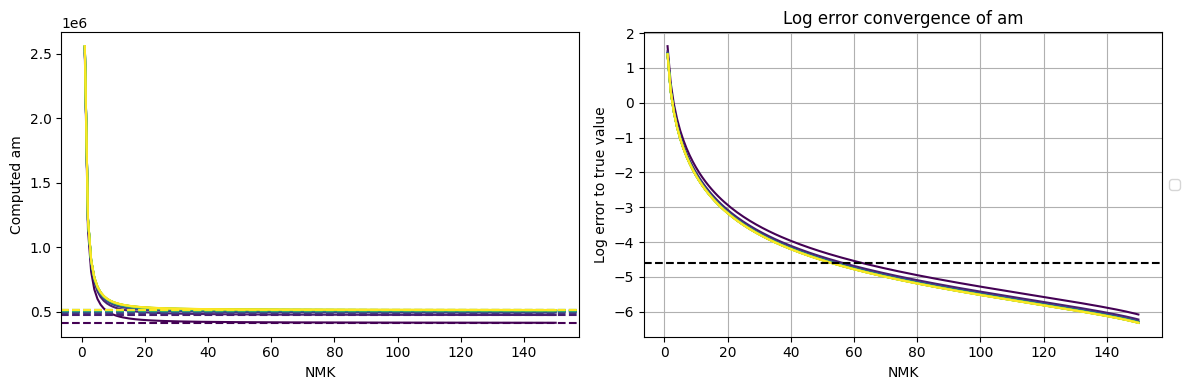

(h-d2)/radwidth2


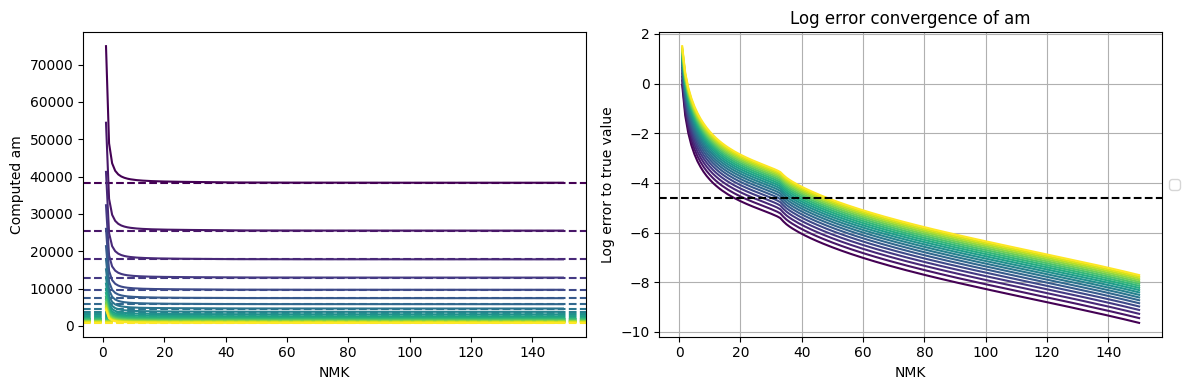

(h-d1)/(h-d2)


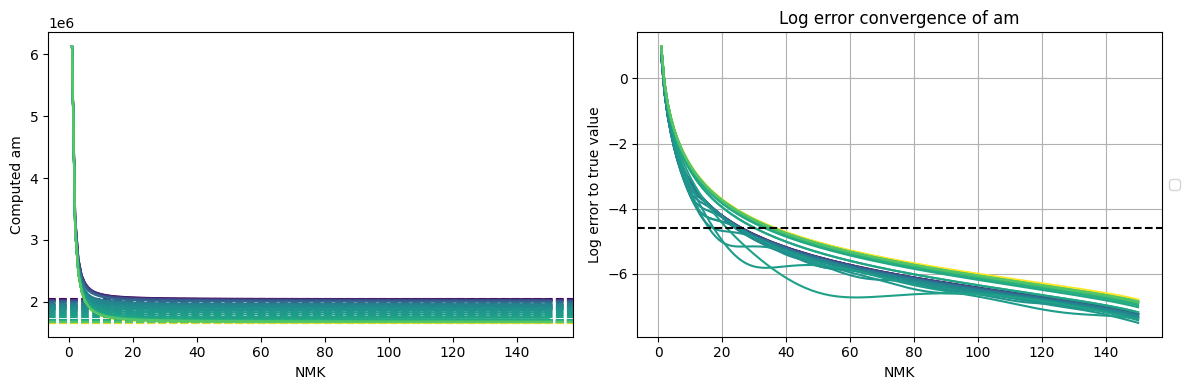

h/(h-d2)


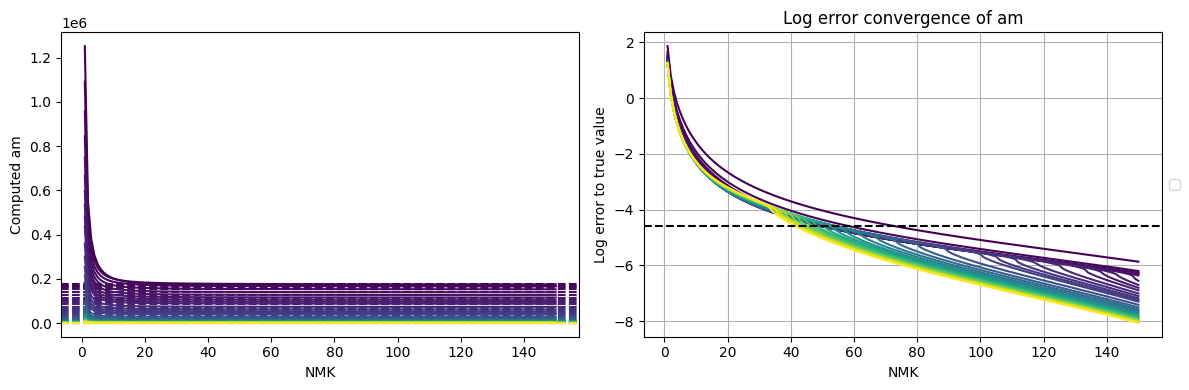

radwidth2/a2


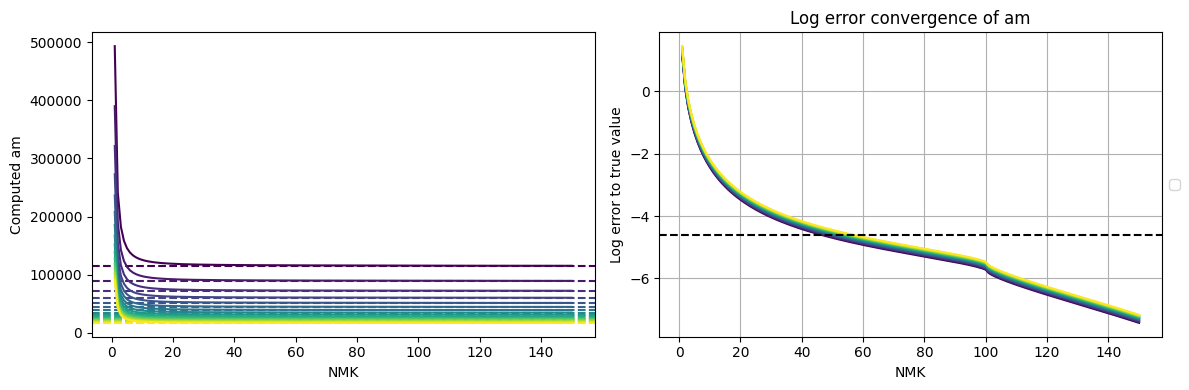

In [8]:
for key in prototypes.keys():
  data = many_data_dicts_to_convergence_plot_data(prototypes[key])
  print(key)
  plot_set_convergence_and_log(data, "am", colors = color_by_f_value(variable_funcs[key], prototypes[key]), show_error = True)

m0h


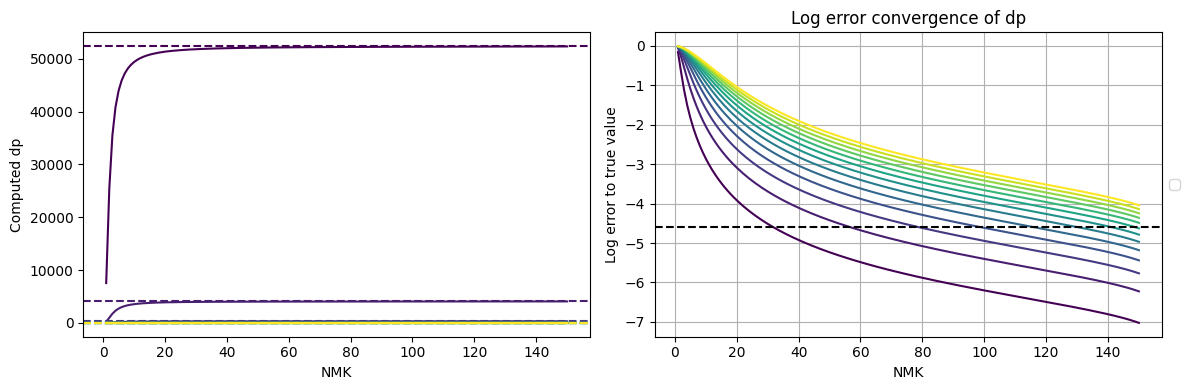

(h-d2)/radwidth2


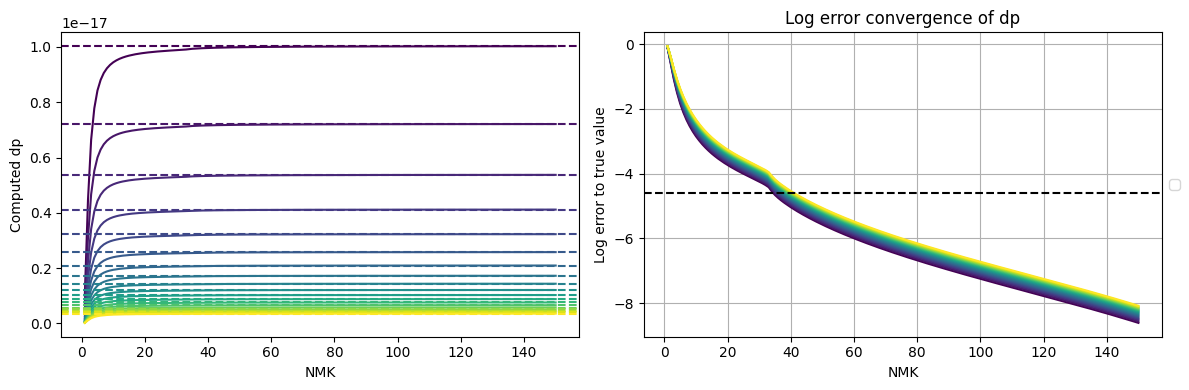

(h-d1)/(h-d2)


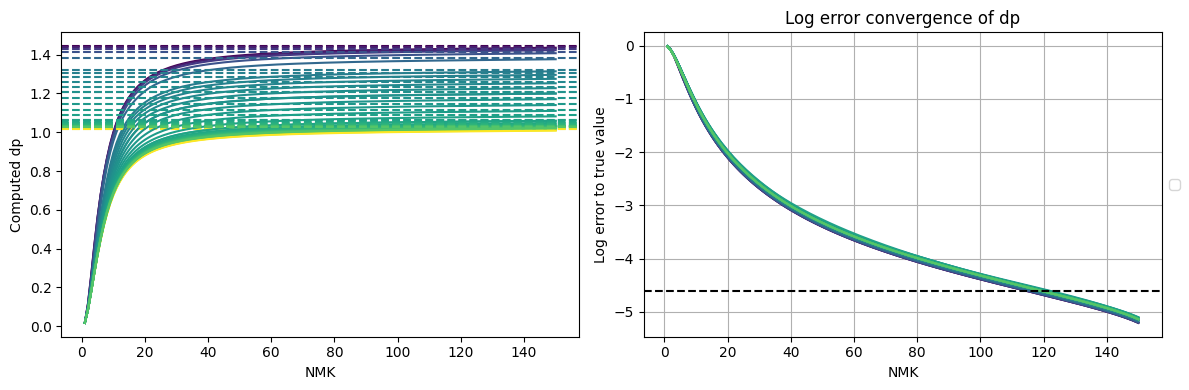

h/(h-d2)


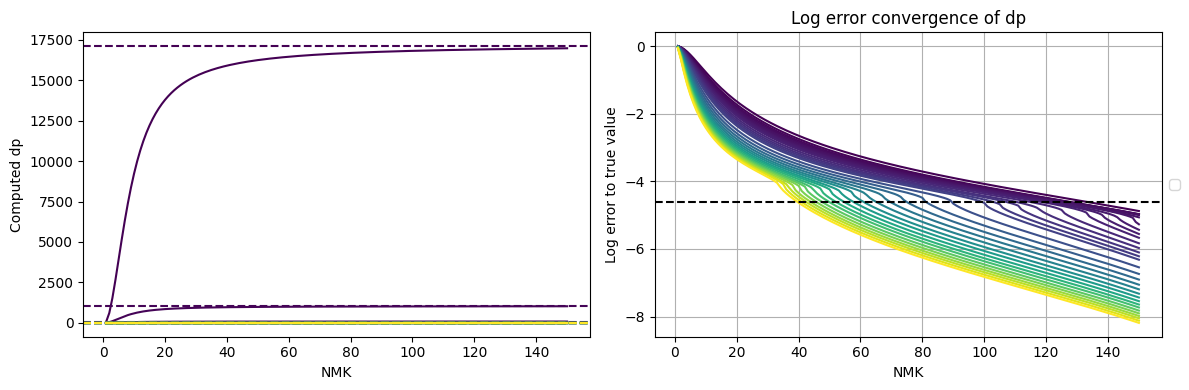

radwidth2/a2


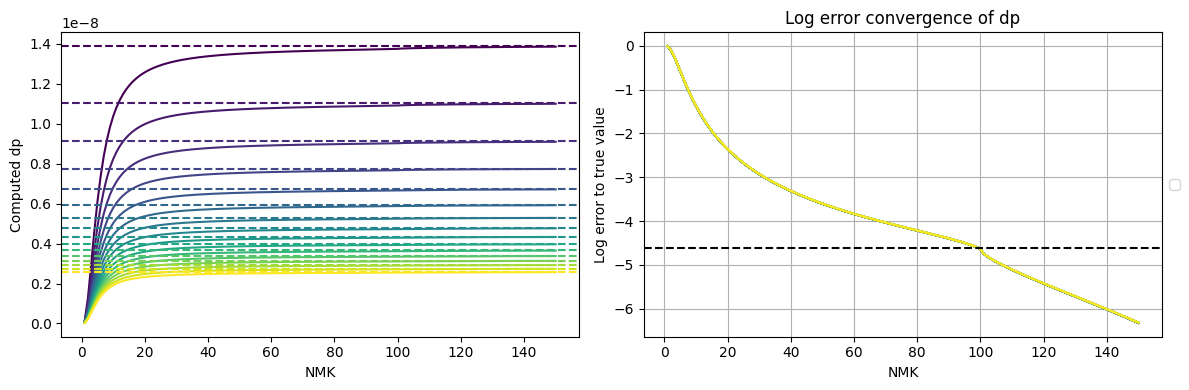

In [9]:
for key in prototypes.keys():
  data = many_data_dicts_to_convergence_plot_data(prototypes[key])
  print(key)
  plot_set_convergence_and_log(data, "dp", colors = color_by_f_value(variable_funcs[key], prototypes[key]), show_error = True)

Plot the fit parameter trends versus dimensionless parameter value.

m0h
Best-fit parameters: [1.44373127 1.32703381]
Best-fit parameters: [1.4090881  2.12886305]
Best-fit parameters: [1.37560215 2.72842569]
Best-fit parameters: [1.34337246 3.22350838]
Best-fit parameters: [1.31268651 3.64768119]
Best-fit parameters: [1.28350955 4.01937595]
Best-fit parameters: [1.25573094 4.3502611 ]
Best-fit parameters: [1.22923493 4.64827616]
Best-fit parameters: [1.20391626 4.91911214]
Best-fit parameters: [1.17968227 5.16701581]
Best-fit parameters: [1.15645182 5.39525801]
Best-fit parameters: [1.1341536  5.60642282]
Best-fit parameters: [1.11272461 5.80259453]


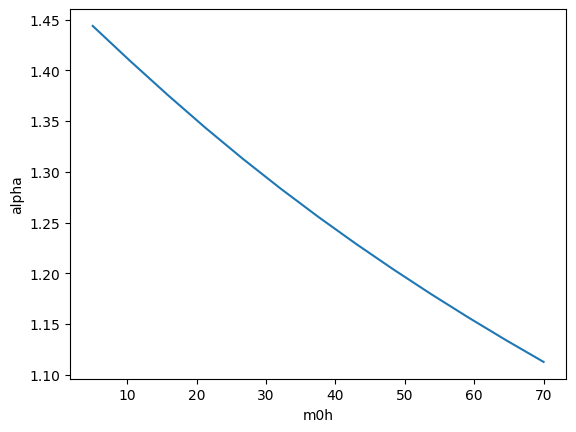

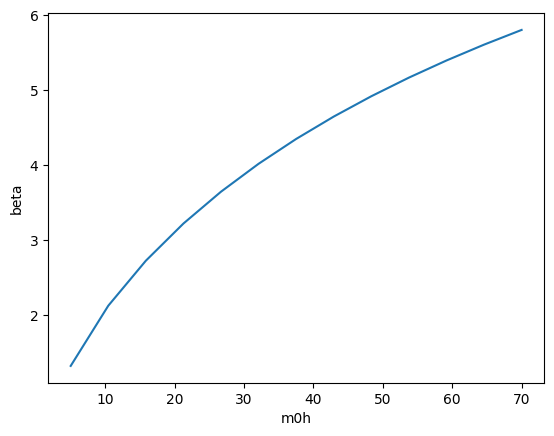

(h-d2)/radwidth2
Best-fit parameters: [1.96661331 2.55344248]
Best-fit parameters: [1.96487431 2.60537018]
Best-fit parameters: [1.96299685 2.65278134]
Best-fit parameters: [1.96100794 2.69641101]
Best-fit parameters: [1.95892796 2.73681441]
Best-fit parameters: [1.95677272 2.77442408]
Best-fit parameters: [1.95455473 2.80958532]
Best-fit parameters: [1.95228403 2.84257894]
Best-fit parameters: [1.94996881 2.87363734]
Best-fit parameters: [1.94761583 2.90295517]
Best-fit parameters: [1.94523069 2.93069749]
Best-fit parameters: [1.94281809 2.95700575]
Best-fit parameters: [1.94038196 2.982002  ]
Best-fit parameters: [1.93792565 3.00579254]
Best-fit parameters: [1.935452   3.02847054]
Best-fit parameters: [1.9329634  3.05011809]
Best-fit parameters: [1.93046193 3.07080808]
Best-fit parameters: [1.92794936 3.09060541]
Best-fit parameters: [1.92542714 3.10956797]


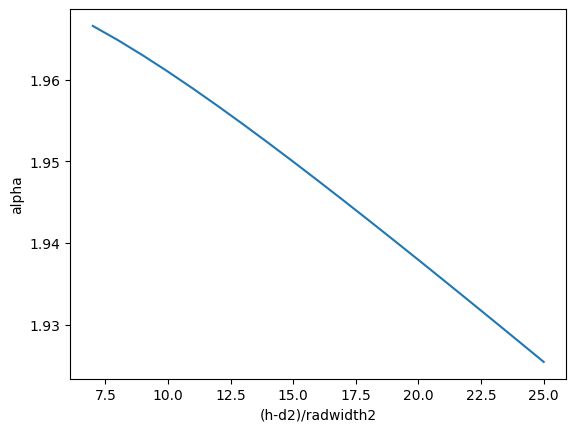

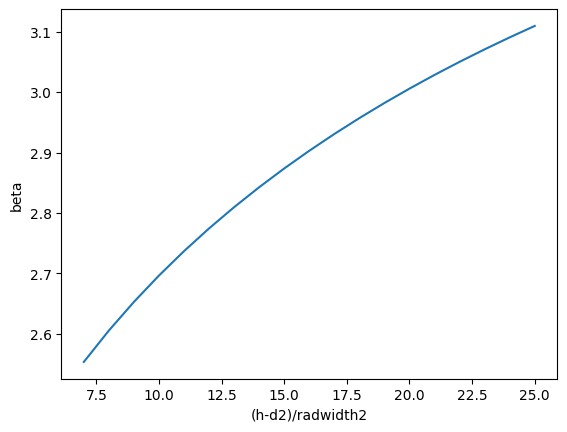

(h-d1)/(h-d2)
Best-fit parameters: [1.3013738  3.44418071]
Best-fit parameters: [1.30145434 3.44801101]
Best-fit parameters: [1.30158508 3.45549138]
Best-fit parameters: [1.3017633  3.47061248]
Best-fit parameters: [1.30186579 3.50155107]
Best-fit parameters: [1.30130213 3.56156363]
Best-fit parameters: [1.3010361  3.57824281]
Best-fit parameters: [1.30062847 3.59605793]
Best-fit parameters: [1.30003993 3.61455933]
Best-fit parameters: [1.29931768 3.63350499]
Best-fit parameters: [1.29865688 3.6530615 ]
Best-fit parameters: [1.29865688 3.6530615 ]
Best-fit parameters: [1.29776374 3.67045682]
Best-fit parameters: [1.2964918  3.68306338]
Best-fit parameters: [1.29496236 3.68868271]
Best-fit parameters: [1.29312341 3.67948976]
Best-fit parameters: [1.2934007  3.62039521]
Best-fit parameters: [1.2934007  3.62039521]
Best-fit parameters: [1.29508049 3.61141058]
Best-fit parameters: [1.29569112 3.60871125]
Best-fit parameters: [1.29636755 3.60881298]
Best-fit parameters: [1.29704332 3.609945

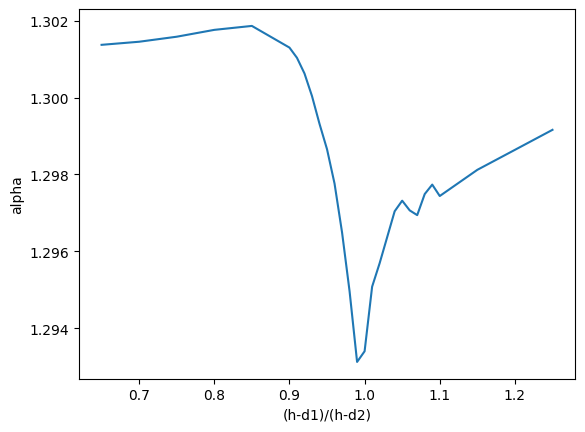

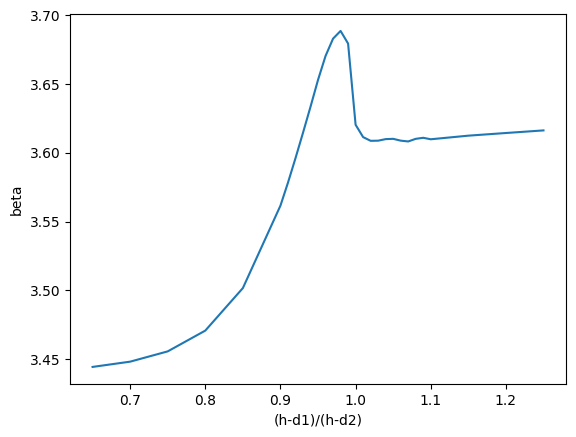

h/(h-d2)
Best-fit parameters: [1.31224715 4.60603669]
Best-fit parameters: [1.32233475 4.39858438]
Best-fit parameters: [1.31198901 4.21268111]
Best-fit parameters: [1.30542104 4.07414696]
Best-fit parameters: [1.29912922 3.94855865]
Best-fit parameters: [1.30036218 3.86344498]
Best-fit parameters: [1.29889134 3.77881335]
Best-fit parameters: [1.31374542 3.76955033]
Best-fit parameters: [1.32665173 3.75937632]
Best-fit parameters: [1.34409299 3.77258905]
Best-fit parameters: [1.37516501 3.78003769]
Best-fit parameters: [1.40966419 3.80122394]
Best-fit parameters: [1.44112902 3.82087246]
Best-fit parameters: [1.47229153 3.83404891]
Best-fit parameters: [1.49935231 3.83572391]
Best-fit parameters: [1.5624859  3.82743788]
Best-fit parameters: [1.61745006 3.8028938 ]
Best-fit parameters: [1.66199052 3.75219963]
Best-fit parameters: [1.70148595 3.69850493]
Best-fit parameters: [1.73581677 3.63865798]
Best-fit parameters: [1.76828204 3.58584308]
Best-fit parameters: [1.79338094 3.51730972]
B

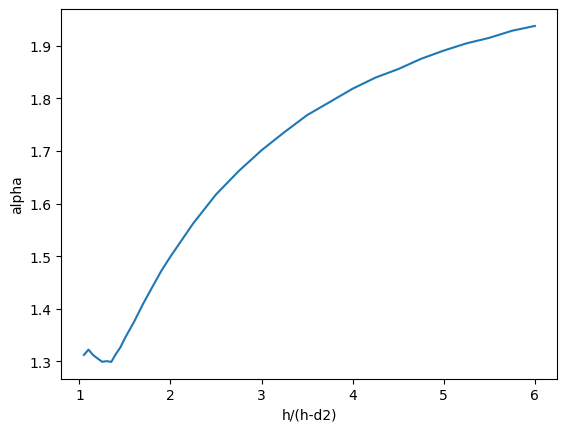

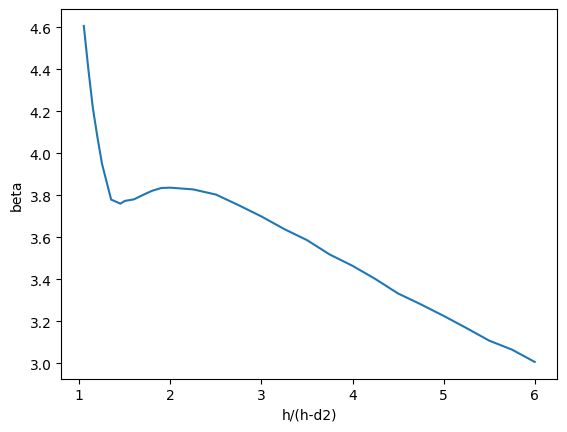

radwidth2/a2
Best-fit parameters: [1.49929044 3.83173871]
Best-fit parameters: [1.49929807 3.83218513]
Best-fit parameters: [1.49930713 3.83272556]
Best-fit parameters: [1.49931732 3.83335397]
Best-fit parameters: [1.4993284  3.83406565]
Best-fit parameters: [1.49934012 3.8348567 ]
Best-fit parameters: [1.49935231 3.83572391]
Best-fit parameters: [1.4993648  3.83666472]
Best-fit parameters: [1.49937747 3.837677  ]
Best-fit parameters: [1.49939015 3.83875858]
Best-fit parameters: [1.49940271 3.83990761]
Best-fit parameters: [1.49941501 3.84112247]
Best-fit parameters: [1.49942695 3.84240191]
Best-fit parameters: [1.49943845 3.84374488]
Best-fit parameters: [1.49944942 3.84515038]
Best-fit parameters: [1.49945979 3.8466176 ]


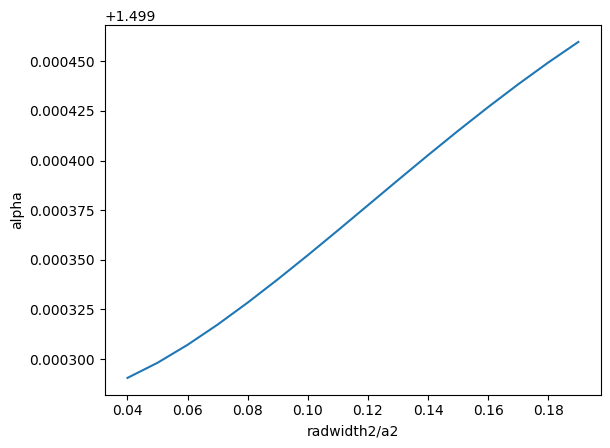

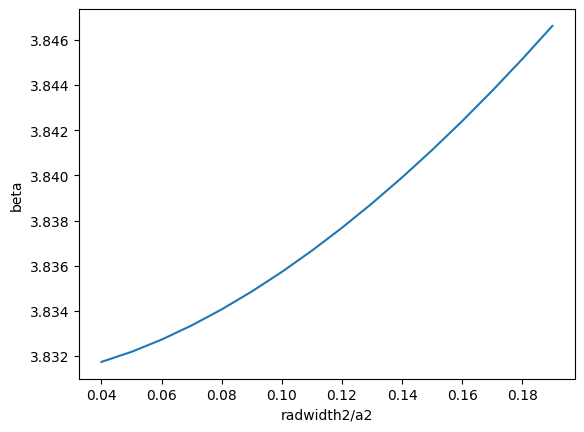

In [35]:
def f(x, a1, a2):
  return - a1 * np.log(x/a2)

for key in prototypes.keys():
  print(key)
  data = prototypes[key]
  data = sorted(data, key=lambda cf: variable_funcs[key](cf, cf["m0s"][0]))
  meta_xs, meta_ys1, meta_ys2 = [], [], []
  for cf in data:
      xs = list(range(1, 151))
      ys = [cf[cf["m0s"][0]]["log errors dp"][i] for i in range(150)]
      # xs, ys = filter_smooth(xs, ys)
      popt, pcov = curve_fit(f, xs, ys, p0=(1, 1))
      print("Best-fit parameters:", popt)
      meta_xs.append(variable_funcs[key](cf, cf["m0s"][0]))
      meta_ys1.append(popt[0])
      meta_ys2.append(popt[1])
      # ys_calc = [f(x, *popt) for x in xs]
      # plt.scatter(xs, ys, label="Data")
      # plt.plot(xs, ys_calc, color="red", label="Fit")
      # plt.legend()
      # plt.show()

  plt.plot(meta_xs, meta_ys1)
  # popt, pcov = curve_fit(meta_f1, meta_xs, meta_ys1, p0=(1, 2, 3))
  # print("Best-fit parameters:", popt)
  # plt.plot(meta_xs, [meta_f1(x, *popt) for x in meta_xs])
  plt.xlabel(key)
  plt.ylabel("alpha")
  plt.show()

  plt.plot(meta_xs, meta_ys2)
  # popt, pcov = curve_fit(meta_f2, meta_xs, meta_ys2, p0=(1, 2, 3))
  # print("Best-fit parameters:", popt)
  # plt.plot(meta_xs, [meta_f1(x, *popt) for x in meta_xs])
  plt.xlabel(key)
  plt.ylabel("beta")
  plt.show()